In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import pickle

# --- Custom imports ---
from Helpers import *   # Contains utility functions for data processing and plotting

# Configure matplotlib for consistent plots
plt.style.use("seaborn-v0_8-whitegrid")

In [2]:
def load_data(file_path):
    """
    Loads a two-column Parquet file and converts it back into a Python dictionary.
    """
    # 1. Read the Parquet file into a DataFrame
    df = pd.read_parquet(file_path)
    
    # 2. Zip the 'key' and 'value' columns together and convert to a dict
    return dict(zip(df['key'], df['value']))

In [3]:
# --- Load data files ---
ROOT_PATH = "/data/pgangwar/vaccinescout/data/"
DATA_PATH = ROOT_PATH +"final_df.parquet"

final_df = pd.read_parquet(DATA_PATH)

parent_node = pd.read_csv(ROOT_PATH + "parent_node.csv", keep_default_na=False)

node_mut_data = pd.read_parquet(ROOT_PATH +'all_nodes_spike_2025-09-01_branch.parquet') 

dates_df = pd.read_csv(ROOT_PATH + 'chronumental_dates_gisaidAndPublic.2025-09-01.metadata.tsv', sep='\t')

ver = 'Jan_4_24'

pyro_df = read_pickle(ROOT_PATH + f'pyro_ver/{ver}/PyroSpike.pkl')

In [4]:
# --- Preprocess Date Data ---
dates_df['predicted_date'] = pd.to_datetime(dates_df['predicted_date'])

dates_df['predicted_date'] = dates_df['predicted_date'].dt.date

dates_df['predicted_date'] = pd.to_datetime(dates_df['predicted_date'])

dates_df = dates_df.rename(columns={'strain': 'node_id'})

In [35]:
# --- Define cutoff date ---
cutoff_date = "2024-06-01"

d = 30

# --- Split dataframe into circulating and future segments ---
_, future_df = split_circulating_and_future(
    final_df,
    cutoff_date_str=cutoff_date,
    left_buffer_days=4,
    right_buffer_days=4,
    circulation_months=None,
    circulation_days=d,
    future_months=12,
    future_days=None
)

# --- Define windows for slicing future data ---
disjoint_windows = ['6M_1', '6M_2']

# --- Perform slicing ---
disjoint_slices = slice_by_disjoint_windows(future_df, disjoint_windows)

# --- Removing sequences seen < 5 sequences in a window ---
future_slices = {}
min_tip_count = 5
for window, df in disjoint_slices.items():  
    # Get the exact occurrence count for every Sequence_ID
    seq_counts = df['Sequence_ID'].value_counts()
    
    # Identify which Sequence_IDs meet or exceed the min_tip_count
    valid_seq_ids = seq_counts[seq_counts >= min_tip_count].index
    
    # Filter the original DataFrame to keep only the valid Sequence_IDs
    filtered_df = df[df['Sequence_ID'].isin(valid_seq_ids)].copy()
    
    # Store the filtered DataFrame in the new dictionary
    future_slices[window] = filtered_df

# --- Summary output ---
print(f"Disjoint slices: {list(disjoint_slices.keys())}")
print(f"Total future slices stored: {len(future_slices)}")

Disjoint slices: ['6M_1', '6M_2']
Total future slices stored: 2


Processing Nodes around Cutoff Date

In [36]:
# --- Filter Nodes around cutoff date ---
filtered_df = dates_df[dates_df['predicted_date'] < cutoff_date]

filtered_df = filtered_df[filtered_df['node_id'].str.contains('node_')]

nodes_before_cutoff = set(filtered_df['node_id'])

In [37]:
# --- Create Lookup Dictionaries ---
parent_node_clean = parent_node.dropna().drop_duplicates(subset=["node"])

parent_lookup = dict(zip(parent_node_clean["node"], parent_node_clean["parent_node"]))

mutations_lookup = dict(zip(node_mut_data['sample_id'], node_mut_data['aa_mutations']))

fitness_lookup = dict(zip(pyro_df['mutation'], pyro_df['R / R_A']))

In [38]:
# --- Apply functions to future data ---
for key, df in future_slices.items():
    df = df.copy()

    # Existing computations
    df["node_path"] = df["Sample_ID"].apply(lambda x: build_node_path(x, parent_lookup))
    df["anchor_remainder"] = df["node_path"].apply(
        lambda path: find_anchor_remainder_reverse(path, nodes_before_cutoff)
    )
    remainder_muts = df["anchor_remainder"].apply(
        lambda ar: get_mutations_from_remainder(ar, mutations_lookup)
    )

    mut_lengths = remainder_muts.str.len()
    mask = mut_lengths > 0
    df = df[mask].copy()

    df["mutations_in_remainder"] = remainder_muts[mask]

    future_slices[key] = df

In [39]:
def get_fitness_list(mutation_list):
    return [fitness_lookup[mut] for mut in mutation_list if mut in fitness_lookup]

for key, df in future_slices.items():
    df['mutations_in_remainder'] = df['mutations_in_remainder'].apply(
        lambda lst: [mut for mut in lst if mut in fitness_lookup]
    )  
    
    df['fitness_in_remainder'] = df['mutations_in_remainder'].apply(get_fitness_list)
    # .str.len() checks the length of the list in each row. We only keep lengths > 0.
    df = df[df['mutations_in_remainder'].str.len() > 0].copy()
    future_slices[key] = df

In [40]:
slice_stats = {}

for key, df in future_slices.items():

    all_mutations = [m for lst in df['mutations_in_remainder'] for m in lst]
    
    slice_stats[key] = {
        "total_mutations": len(all_mutations),
        "unique_mutations": len(set(all_mutations)),
        "total_sequences": len(df)  
    }

In [41]:
# --- Compute fitness frequency distributions ---
fitness_freqs = {}

for key, df in future_slices.items():
    # Flatten all fitness scores across tips seen after the cutoff
    all_fitness = [f for lst in df['fitness_in_remainder'] for f in lst if f is not None]
    
    # Count frequency of each score
    freq_df = pd.Series(all_fitness).value_counts().reset_index()
    freq_df.columns = ["fitness_score", "frequency"]
    
    # Store in dict
    fitness_freqs[key] = freq_df

fitness_freqs_normalized = {}

for key, freq_df in fitness_freqs.items():
    total_mutations = slice_stats[key]["total_mutations"]

    # add a normalized percentage column
    freq_df = freq_df.copy()
    freq_df["percent"] = (freq_df["frequency"] / total_mutations) * 100

    fitness_freqs_normalized[key] = freq_df

Process Mutation Counts

In [42]:
import numpy as np

# Expanded range to guarantee NO data is dropped before being caught by the corner bins
bin_edges = np.arange(0.0, 2.0 + 0.01, 0.0001)

bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

binned_results = {}

for key, df in fitness_freqs_normalized.items():
    # sum percent in each bin
    binned, _ = np.histogram(
        df["fitness_score"],
        bins=bin_edges,
        weights=df["percent"]  # sum of percentages
    )

    binned_results[key] = pd.DataFrame({
        "bin_center": bin_centers,
        "percent_sum": binned
    })

Plot Results

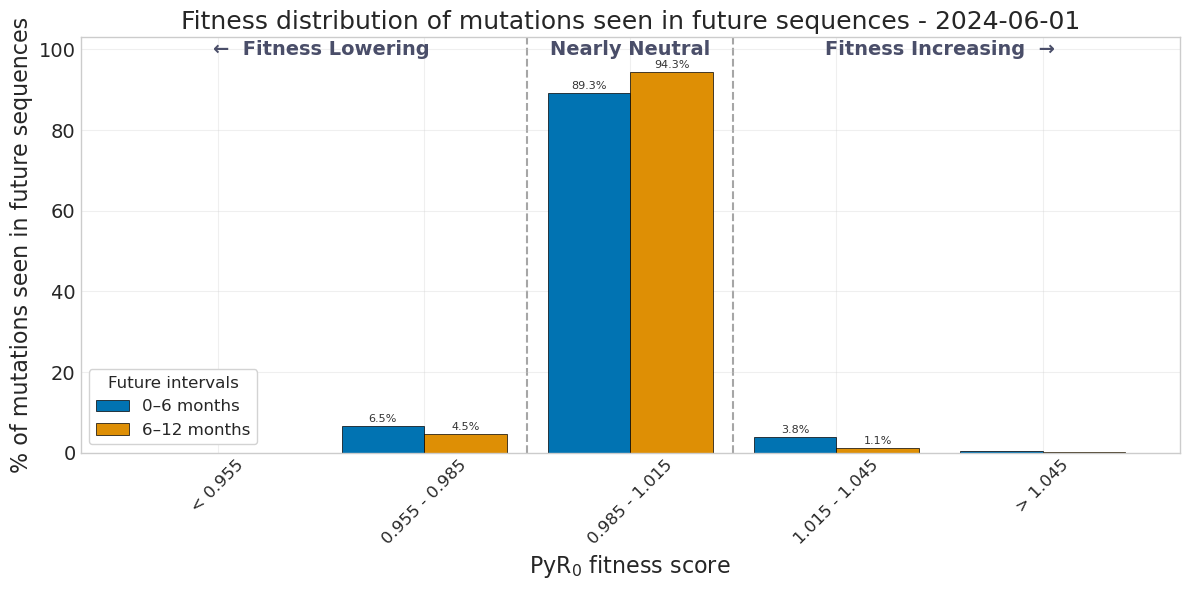

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

legend_labels = {
    "6M_1": "0–6 months",
    "6M_2": "6–12 months"
}

# seaborn colorblind palette
palette = sns.color_palette("colorblind", n_colors=len(disjoint_windows))
slice_colors = {key: palette[i] for i, key in enumerate(disjoint_windows)}

plt.figure(figsize=(12, 6))

total_slices = len(disjoint_windows)
target_bin_size = 0.03  # Updated to match the new 0.03 bin widths
group_width = target_bin_size * 0.8
bar_width = group_width / total_slices

for i, key in enumerate(disjoint_windows):
    df = binned_results[key].copy()
    
    # Update conditions to the new 0.03 width boundaries
    conditions = [
        df["bin_center"] < 0.955,
        (df["bin_center"] >= 0.955) & (df["bin_center"] < 0.985),
        (df["bin_center"] >= 0.985) & (df["bin_center"] < 1.015),
        (df["bin_center"] >= 1.015) & (df["bin_center"] < 1.045),
        df["bin_center"] >= 1.045
    ]
    
    # Updated visual x-coordinates (spaced exactly 0.03 apart)
    choices = [0.94, 0.97, 1.00, 1.03, 1.06]
    df["coarse_bin"] = np.select(conditions, choices)
    
    df_grouped = df.groupby("coarse_bin", as_index=False)["percent_sum"].sum()  
    x = df_grouped["coarse_bin"].to_numpy()
    y = df_grouped["percent_sum"].to_numpy()

    offset = (i - (total_slices - 1) / 2) * bar_width

    plt.bar(
        x + offset, y, 
        width=bar_width, 
        color=slice_colors[key], 
        label=legend_labels[key], 
        alpha=1.0,            
        edgecolor='black',   
        linewidth=0.5
    )

    for val_x, val_y in zip(x + offset, y):
        if val_y > 0.5:  
            plt.text(
                val_x, val_y + 0.5,      
                f"{val_y:.1f}%",        
                ha='center', va='bottom', 
                fontsize=8,                
                rotation=0,              
                color='#333333'            
            )

try:
    plt.title(f'Fitness distribution of mutations seen in future sequences - {cutoff_date}', fontsize=18)
except NameError:
    plt.title('Fitness distribution of mutations seen in future sequences', fontsize=18)

plt.xlabel("PyR$_0$ fitness score", fontsize=16)
plt.ylabel("% of mutations seen in future sequences", fontsize=16)
leg = plt.legend(title="Future intervals", fontsize=12, title_fontsize=12, 
                 frameon=True, facecolor='white', edgecolor='lightgray', framealpha=1.0)
leg.set_zorder(100)

# Expanded x-limits to cleanly fit the new 0.94 and 1.06 anchors
plt.xlim(0.92, 1.08)

# Set the new ticks and labels
clean_ticks = [0.94, 0.97, 1.00, 1.03, 1.06]
tick_labels = ["< 0.955", "0.955 - 0.985", "0.985 - 1.015", "1.015 - 1.045", "> 1.045"]

plt.xticks(ticks=clean_ticks, labels=tick_labels, rotation=45, fontsize=12)
plt.gca().ticklabel_format(axis='y', useOffset=False, style='plain')

plt.yticks(fontsize=14)
plt.grid(alpha=0.3)
plt.ylim(0, 103)

# Realign the vertical threshold lines to match the central bin boundaries
plt.axvline(x=0.985, color='gray', linestyle='--', linewidth=1.5, alpha=0.7, zorder=0)
plt.axvline(x=1.015, color='gray', linestyle='--', linewidth=1.5, alpha=0.7, zorder=0)

# Re-center text annotations over the new groups
plt.text(
    x=0.955, y=100, 
    s="←  Fitness Lowering", 
    ha='center', va='center', 
    fontsize=14, fontweight='bold', color='#4a4e69'
)
plt.text(
    x=1.00, y=100, 
    s="Nearly Neutral", 
    ha='center', va='center', 
    fontsize=14, fontweight='bold', color='#4a4e69'
)
plt.text(
    x=1.045, y=100, 
    s="Fitness Increasing  →", 
    ha='center', va='center', 
    fontsize=14, fontweight='bold', color='#4a4e69'
)

plt.tight_layout()
plt.savefig(Path(ROOT_PATH) / cutoff_date / 'fitness.svg', format='svg', bbox_inches='tight', dpi=300)
plt.show()